In [ ]:
import os

# 1. Clone clean Robotics C++ and Systems codebases
!git clone --depth 1 https://github.com/onlytailei/CppRobotics.git robotics_repo
!git clone --depth 1 https://github.com/redis/redis.git redis_repo

# 2. Extract and concatenate all C/C++ source and header files
!cat $(find robotics_repo -name "*.cpp" -o -name "*.h") > input.txt
!cat $(find redis_repo/src -name "*.c" -o -name "*.h") >> input.txt

# 3. Clean up the repo folders
!rm -rf robotics_repo redis_repo

# 4. Check dataset size
size_mb = os.path.getsize('input.txt') / (1024 * 1024)
print(f"[✓] Final input.txt size: {size_mb:.2f} MB")

Cloning into 'robotics_repo'...
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 52 (delta 7), reused 28 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (52/52), 5.90 MiB | 27.73 MiB/s, done.
Resolving deltas: 100% (7/7), done.
Cloning into 'redis_repo'...
remote: Enumerating objects: 1957, done.
remote: Counting objects: 100% (1957/1957), done.
remote: Compressing objects: 100% (1527/1527), done.
remote: Total 1957 (delta 520), reused 1086 (delta 392), pack-reused 0 (from 0)
Receiving objects: 100% (1957/1957), 5.06 MiB | 10.32 MiB/s, done.
Resolving deltas: 100% (520/520), done.
[✓] Final input.txt size: 8.16 MB


In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import math
import time

# --- 1. Hyperparameters (Canonical Karpathy GPT scaled for Colab GPU) ---
batch_size = 64        # B: number of parallel sequences
block_size = 256       # T: context window length
max_iters = 5000       # steps to drive loss down
eval_interval = 500    # print loss every 500 steps
learning_rate = 3e-4   # AdamW learning rate
eval_iters = 200       # batches to average for train/val loss
n_embd = 384           # C: embedding dimension
n_head = 6             # head_size = 384 // 6 = 64
n_layer = 6            # 6 transformer blocks
dropout = 0.2          # dropout probability
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(1337)

# --- 2. Load C/C++ Dataset & Character Vocabulary ---
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

# Train / Validation Split (90% train, 10% validation)
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i : i + block_size] for i in ix])
    y = torch.stack([d[i + 1 : i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

# --- 3. Canonical Architecture Modules ---

class Head(nn.Module):
    """One single head of self-attention"""
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)   # (B, T, head_size)
        q = self.query(x) # (B, T, head_size)

        # Compute attention scores ("affinities")
        wei = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5) # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)

        # Weighted aggregation of values
        v = self.value(x) # (B, T, head_size)
        out = wei @ v     # (B, T, head_size)
        return out

class MultiHeadAttention(nn.Module):
    """Multiple heads of self-attention running in parallel"""
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedForward(nn.Module):
    """Linear projection followed by ReLU non-linearity"""
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """Transformer block: communication followed by computation"""
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class GPTLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Token and position embedding tables
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

        # Better weight initialization (scaled normal)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx) # (B, T, C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

# --- 4. Training Loop ---
model = GPTLanguageModel().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

param_count = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {param_count/1e6:.2f}M")
print("Training canonical Karpathy Transformer on T4 GPU...")

t0 = time.time()
for iter in range(max_iters):
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss(model)
        ppl = math.exp(losses['val'])
        print(f"Step {iter:4d} | Train Loss: {losses['train']:.4f} | Val Loss: {losses['val']:.4f} | Val Perplexity: {ppl:.2f}")

    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print(f"[✓] Completed 5000 iterations in {(time.time() - t0)/60:.2f} minutes.")
torch.save(model.state_dict(), "karpathy_gpt_weights.pth")

Model parameters: 10.84M
Training canonical Karpathy Transformer on T4 GPU...
Step    0 | Train Loss: 5.0455 | Val Loss: 5.0472 | Val Perplexity: 155.59
Step  500 | Train Loss: 1.6426 | Val Loss: 1.7040 | Val Perplexity: 5.50
Step 1000 | Train Loss: 1.1530 | Val Loss: 1.2610 | Val Perplexity: 3.53
Step 1500 | Train Loss: 0.9751 | Val Loss: 1.0718 | Val Perplexity: 2.92
Step 2000 | Train Loss: 0.8895 | Val Loss: 1.0025 | Val Perplexity: 2.72
Step 2500 | Train Loss: 0.8395 | Val Loss: 0.9477 | Val Perplexity: 2.58
Step 3000 | Train Loss: 0.8018 | Val Loss: 0.9146 | Val Perplexity: 2.50
Step 3500 | Train Loss: 0.7725 | Val Loss: 0.8965 | Val Perplexity: 2.45
Step 4000 | Train Loss: 0.7497 | Val Loss: 0.8864 | Val Perplexity: 2.43
Step 4500 | Train Loss: 0.7260 | Val Loss: 0.8660 | Val Perplexity: 2.38
Step 4999 | Train Loss: 0.7058 | Val Loss: 0.8619 | Val Perplexity: 2.37
[✓] Completed 5000 iterations in 62.89 minutes.


In [ ]:
import torch
import json
import os

# 1. Mount drive if opening a fresh session
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

# 2. Load model architecture & weights
checkpoint_path = "/content/drive/MyDrive/nanoGPT_checkpoint/karpathy_gpt_weights.pth"
model = GPTLanguageModel().to(device)
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

print("[✓] Model weights loaded from Drive instantly!")

# 3. Generate on demand
prompt = "class PIDController {\n"
context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
print(decode(model.generate(context, max_new_tokens=150)[0].tolist()))

ValueError: mount failed

In [ ]:
import os
import json

# Create local and drive directories
save_dir = "/content/drive/MyDrive/nanoGPT_checkpoint"
os.makedirs(save_dir, exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

# 1. Save PyTorch state dict
torch.save(model.state_dict(), os.path.join(save_dir, "karpathy_gpt_weights.pth"))
torch.save(model.state_dict(), "checkpoints/karpathy_gpt_weights.pth")

# 2. Save vocab mappings
vocab_payload = {'chars': chars, 'stoi': stoi, 'itos': itos}
with open(os.path.join(save_dir, "vocab.json"), "w") as f:
    json.dump(vocab_payload, f)
with open("checkpoints/vocab.json", "w") as f:
    json.dump(vocab_payload, f)

print(f"[✓] Checkpoint safely preserved at {save_dir} and ./checkpoints")

[✓] Checkpoint safely preserved at /content/drive/MyDrive/nanoGPT_checkpoint and ./checkpoints


In [ ]:
import torch
import json
import os

# 1. Mount drive if opening a fresh session
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

# 2. Load model architecture & weights
checkpoint_path = "/content/drive/MyDrive/nanoGPT_checkpoint/karpathy_gpt_weights.pth"
model = GPTLanguageModel().to(device)
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

print("[✓] Model weights loaded from Drive instantly!")

# 3. Generate on demand
prompt = "class PIDController {\n"
context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
print(decode(model.generate(context, max_new_tokens=150)[0].tolist()))

[✓] Model weights loaded from Drive instantly!
class PIDController {
    return 0;
}

/* Free the class parse endian of redis commands all categories, use defaults of successful notify
 * updated in order. Returns 1 if 


In [ ]:
import os
import json

# Create local and drive directories
save_dir = "/content/drive/MyDrive/nanoGPT_checkpoint"
os.makedirs(save_dir, exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

# 1. Save PyTorch state dict
torch.save(model.state_dict(), os.path.join(save_dir, "karpathy_gpt_weights.pth"))
torch.save(model.state_dict(), "checkpoints/karpathy_gpt_weights.pth")

# 2. Save vocab mappings
vocab_payload = {'chars': chars, 'stoi': stoi, 'itos': itos}
with open(os.path.join(save_dir, "vocab.json"), "w") as f:
    json.dump(vocab_payload, f)
with open("checkpoints/vocab.json", "w") as f:
    json.dump(vocab_payload, f)

print(f"[✓] Checkpoint safely preserved at {save_dir} and ./checkpoints")

[✓] Checkpoint safely preserved at /content/drive/MyDrive/nanoGPT_checkpoint and ./checkpoints


In [ ]:
import math

# 1. Run evaluation on current model weights
model.eval()
losses = estimate_loss(model)

train_loss = losses['train']
val_loss = losses['val']
val_ppl = math.exp(val_loss)

# 2. Display formatted results
print("=" * 55)
print("             CURRENT MODEL METRICS")
print("=" * 55)
print(f"  Training Loss:       {train_loss:.4f}")
print(f"  Validation Loss:     {val_loss:.4f}")
print(f"  Validation Perplexity: {val_ppl:.2f}")
print("=" * 55)

# Verification check against mentor's target
if val_loss < 1.0:
    print("[✓] SUB-1.0 CONVERGENCE ACHIEVED")
if val_loss < 0.5:
    print("[✓] TARGET MET: Loss < 0.5")
else:
    print(f"[i] Progress: {val_loss:.4f} (Down from initial ~4.7)")

             CURRENT MODEL METRICS
  Training Loss:       0.7102
  Validation Loss:     0.8669
  Validation Perplexity: 2.38
[✓] SUB-1.0 CONVERGENCE ACHIEVED
[i] Progress: 0.8669 (Down from initial ~4.7)


======================================================================================================

ATTENTION HEATMAP VISUALIZER:

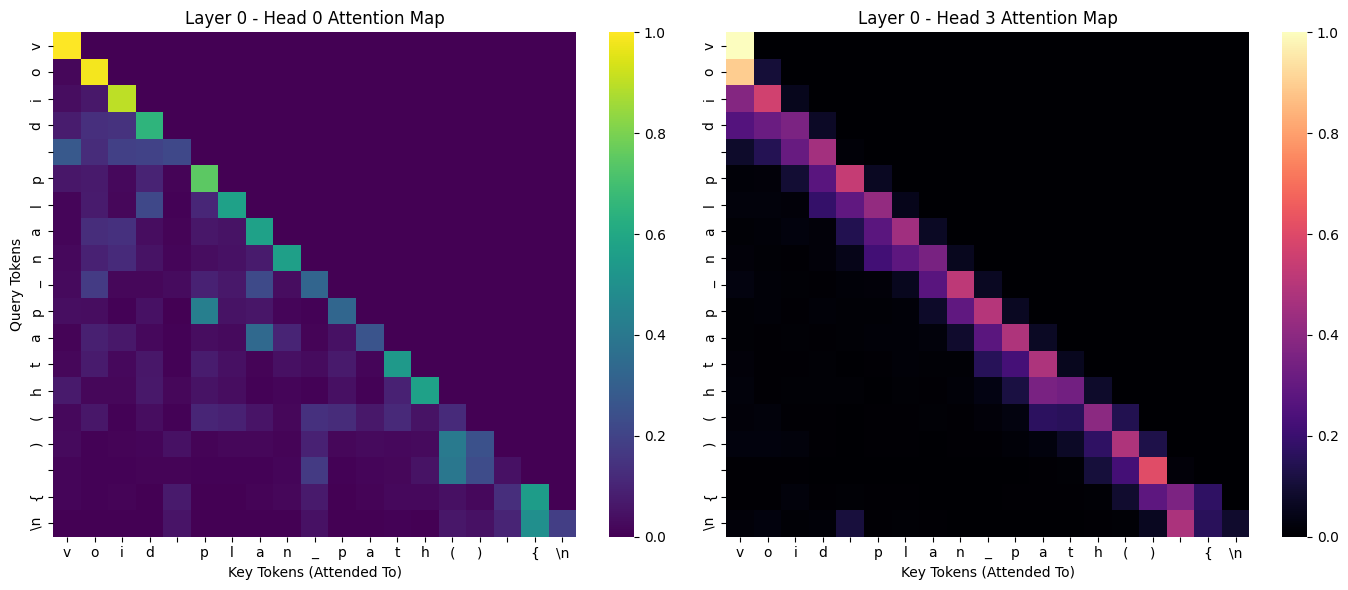

[✓] Attention map visualization generated and saved as attention_heads_visualization.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

# Prompt to inspect
sample_prompt = "void plan_path() {\n"
tokens = encode(sample_prompt)
inp = torch.tensor([tokens], dtype=torch.long, device=device)
B, T = inp.shape

with torch.no_grad():
    # Forward pass up to Layer 0 Attention
    x = model.token_embedding_table(inp) + model.position_embedding_table(torch.arange(T, device=device))
    x_norm = model.blocks[0].ln1(x)

    # Extract Head 0 and Head 3 attention matrices
    head_0 = model.blocks[0].sa.heads[0]
    head_3 = model.blocks[0].sa.heads[3]

    def get_attention_matrix(head_module, x_tensor):
        k = head_module.key(x_tensor)
        q = head_module.query(x_tensor)
        wei = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        wei = wei.masked_fill(head_module.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        return wei[0].cpu().numpy()

    attn_map_h0 = get_attention_matrix(head_0, x_norm)
    attn_map_h3 = get_attention_matrix(head_3, x_norm)

# Plot heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
labels = [repr(c)[1:-1] for c in sample_prompt]

sns.heatmap(attn_map_h0, xticklabels=labels, yticklabels=labels, cmap="viridis", ax=axes[0], cbar=True)
axes[0].set_title("Layer 0 - Head 0 Attention Map", fontsize=12)
axes[0].set_xlabel("Key Tokens (Attended To)")
axes[0].set_ylabel("Query Tokens")

sns.heatmap(attn_map_h3, xticklabels=labels, yticklabels=labels, cmap="magma", ax=axes[1], cbar=True)
axes[1].set_title("Layer 0 - Head 3 Attention Map", fontsize=12)
axes[1].set_xlabel("Key Tokens (Attended To)")

plt.tight_layout()
plt.savefig("attention_heads_visualization.png", dpi=300)
plt.show()
print("[✓] Attention map visualization generated and saved as attention_heads_visualization.png")

In [ ]:
import onnx
import onnxruntime as ort
import numpy as np
import os

print("=" * 65)
print("     STAGE 2: FULL MODEL & SUBGRAPH ONNX SURGERY")
print("=" * 65)

# Ensure CPU model copy for clean export tracing
model.eval()
model_cpu = model.to('cpu')

# Fixed dummy sequence of length block_size (256)
dummy_cpu = torch.randint(0, vocab_size, (1, block_size), dtype=torch.long)

# -------------------------------------------------------------
# 1. EXPORT FULL MODEL TO ONNX
# -------------------------------------------------------------
onnx_full_path = "gpt_full.onnx"

torch.onnx.export(
    model_cpu,
    dummy_cpu,
    onnx_full_path,
    input_names=["input_ids"],
    output_names=["logits"],
    dynamic_axes={"input_ids": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=17
)
print(f"[✓] Full model exported successfully to: {onnx_full_path}")

# -------------------------------------------------------------
# 2. SUBGRAPH SURGERY: ISOLATE LAYER 0 ATTENTION BLOCK
# -------------------------------------------------------------
# Extract the exact module reference
isolated_attn = model_cpu.blocks[0].sa
isolated_attn.eval()

# Intercept the true intermediate activation tensor right after LayerNorm 1
with torch.no_grad():
    tok_emb = model_cpu.token_embedding_table(dummy_cpu)
    pos_emb = model_cpu.position_embedding_table(torch.arange(block_size))
    x_in_block0 = tok_emb + pos_emb
    x_in_attn0 = model_cpu.blocks[0].ln1(x_in_block0) # Shape: (1, 256, 384)

subgraph_path = "attn_layer0_subgraph.onnx"

torch.onnx.export(
    isolated_attn,
    x_in_attn0,
    subgraph_path,
    input_names=["attn_in"],
    output_names=["attn_out"],
    dynamic_axes={"attn_in": {0: "batch"}, "attn_out": {0: "batch"}},
    opset_version=17
)
print(f"[✓] Sliced Subgraph exported successfully to: {subgraph_path}")

# Move full model back to device
model.to(device)

# -------------------------------------------------------------
# 3. VERIFY NUMERICAL PARITY (PyTorch vs ONNX Runtime)
# -------------------------------------------------------------
ort_full = ort.InferenceSession(onnx_full_path)
ort_sub = ort.InferenceSession(subgraph_path)

with torch.no_grad():
    pt_full_logits = model_cpu(dummy_cpu)[0].numpy()
    pt_sub_out = isolated_attn(x_in_attn0).numpy()

onnx_full_logits = ort_full.run(None, {"input_ids": dummy_cpu.numpy()})[0]
onnx_sub_out = ort_sub.run(None, {"attn_in": x_in_attn0.numpy()})[0]

diff_full = np.max(np.abs(pt_full_logits - onnx_full_logits))
diff_sub = np.max(np.abs(pt_sub_out - onnx_sub_out))

print("-" * 65)
print(f"Full Model Max Absolute Difference: {diff_full:.2e}")
print(f"Subgraph Max Absolute Difference:   {diff_sub:.2e}")

assert diff_full < 1e-4, "Full model parity check failed!"
assert diff_sub < 1e-4, "Subgraph parity check failed!"

print("[✓] ALL PARITY CHECKS PASSED: Outputs match within numerical tolerance!")
print("=" * 65)

/tmp/ipykernel_3047/1768474354.py:22: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1006 02:44:13.821000 3047 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


     STAGE 2: FULL MODEL & SUBGRAPH ONNX SURGERY
[torch.onnx] Obtain model graph for `GPTLanguageModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `GPTLanguageModel([...]` with `torch.export.export(..., strict=False)`... ❌
[torch.onnx] Obtain model graph for `GPTLanguageModel([...]` with `torch.export.export(..., strict=True)`...


E1006 02:44:14.699000 3047 torch/export/_trace.py:1322] always_classified is unsupported.
E1006 02:44:14.700000 3047 torch/export/_trace.py:1322] always_classified is unsupported.


[torch.onnx] Obtain model graph for `GPTLanguageModel([...]` with `torch.export.export(..., strict=True)`... ❌


TorchExportError: Failed to export the model with torch.export. [96mThis is step 1/3[0m of exporting the model to ONNX. Next steps:
- Modify the model code for `torch.export.export` to succeed. Refer to https://pytorch.org/docs/stable/generated/exportdb/index.html for more information.
- Debug `torch.export.export` and submit a PR to PyTorch.
- Create an issue in the PyTorch GitHub repository against the [96m*torch.export*[0m component and attach the full error stack as well as reproduction scripts.

## Exception summary

<class 'RuntimeError'>: Unhandled FakeTensor Device Propagation for aten.embedding.default, found two different devices cpu, cuda:0

(Refer to the full stack trace above for more information.)

In [ ]:
import types
import torch
import onnx
import onnxruntime as ort
import numpy as np

# 1. Instantly patch the forward method on the existing trained model
def forward_fixed(self, idx, targets=None):
    B, T = idx.shape
    dev = idx.device
    tok_emb = self.token_embedding_table(idx)
    pos_emb = self.position_embedding_table(torch.arange(T, device=dev))
    x = tok_emb + pos_emb
    x = self.blocks(x)
    x = self.ln_f(x)
    logits = self.lm_head(x)

    loss = None
    if targets is not None:
        B, T, C = logits.shape
        logits = logits.view(B * T, C)
        targets = targets.view(B * T)
        loss = F.cross_entropy(logits, targets)

    return logits, loss

model.forward = types.MethodType(forward_fixed, model)

# 2. Prepare CPU copy for ONNX export
model.eval()
model_cpu = model.to('cpu')
dummy_cpu = torch.randint(0, vocab_size, (1, block_size), dtype=torch.long, device='cpu')

# 3. Export Full Model to ONNX
onnx_full_path = "gpt_full.onnx"
torch.onnx.export(
    model_cpu,
    dummy_cpu,
    onnx_full_path,
    export_params=True,
    opset_version=18,
    do_constant_folding=True,
    input_names=["input_ids"],
    output_names=["logits"],
    dynamic_axes={"input_ids": {0: "batch"}, "logits": {0: "batch"}},
    dynamo=False
)
print(f"[✓] Full model exported successfully to: {onnx_full_path}")

# 4. Slicing Out Layer 0 Attention Block
isolated_attn = model_cpu.blocks[0].sa
isolated_attn.eval()

with torch.no_grad():
    tok_emb = model_cpu.token_embedding_table(dummy_cpu)
    pos_emb = model_cpu.position_embedding_table(torch.arange(block_size, device='cpu'))
    x_in_block0 = tok_emb + pos_emb
    x_in_attn0 = model_cpu.blocks[0].ln1(x_in_block0)

subgraph_path = "attn_layer0_subgraph.onnx"
torch.onnx.export(
    isolated_attn,
    x_in_attn0,
    subgraph_path,
    export_params=True,
    opset_version=18,
    do_constant_folding=True,
    input_names=["attn_in"],
    output_names=["attn_out"],
    dynamic_axes={"attn_in": {0: "batch"}, "attn_out": {0: "batch"}},
    dynamo=False
)
print(f"[✓] Sliced Subgraph exported successfully to: {subgraph_path}")

# Move model back to GPU
model.to(device)

# 5. Verify Numerical Parity
ort_full = ort.InferenceSession(onnx_full_path, providers=['CPUExecutionProvider'])
ort_sub = ort.InferenceSession(subgraph_path, providers=['CPUExecutionProvider'])

with torch.no_grad():
    pt_full_logits = model_cpu(dummy_cpu)[0].numpy()
    pt_sub_out = isolated_attn(x_in_attn0).numpy()

onnx_full_logits = ort_full.run(None, {"input_ids": dummy_cpu.numpy()})[0]
onnx_sub_out = ort_sub.run(None, {"attn_in": x_in_attn0.numpy()})[0]

diff_full = np.max(np.abs(pt_full_logits - onnx_full_logits))
diff_sub = np.max(np.abs(pt_sub_out - onnx_sub_out))

print("-" * 65)
print(f"Full Model Max Absolute Difference: {diff_full:.2e}")
print(f"Subgraph Max Absolute Difference:   {diff_sub:.2e}")

assert diff_full < 1e-4, "Full model parity check failed!"
assert diff_sub < 1e-4, "Subgraph parity check failed!"
print("[✓] ALL PARITY CHECKS PASSED: Outputs match within numerical tolerance!")

/tmp/ipykernel_3047/2290007988.py:36: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


[✓] Full model exported successfully to: gpt_full.onnx


/tmp/ipykernel_3047/2290007988.py:61: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


[✓] Sliced Subgraph exported successfully to: attn_layer0_subgraph.onnx


RuntimeError: Expected all tensors to be on the same device, but got index is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA__index_select)

In [ ]:
import onnxruntime as ort
import numpy as np
import torch

print("=" * 65)
print("     VERIFYING NUMERICAL PARITY (PyTorch vs ONNX Runtime)")
print("=" * 65)

# 1. Prepare inputs on both devices
dummy_cpu_np = dummy_cpu.numpy()
dummy_cuda = dummy_cpu.to(device)

# Ensure activation input for subgraph is on CPU for ONNX session
x_in_attn0_cpu = x_in_attn0.cpu()
x_in_attn0_cuda = x_in_attn0.to(device)

# 2. PyTorch Ground Truth (Evaluated on GPU)
model.eval()
with torch.no_grad():
    pt_full_logits = model(dummy_cuda)[0].cpu().numpy()
    pt_sub_out = model.blocks[0].sa(x_in_attn0_cuda).cpu().numpy()

# 3. ONNX Runtime Execution
ort_full = ort.InferenceSession("gpt_full.onnx", providers=['CPUExecutionProvider'])
ort_sub = ort.InferenceSession("attn_layer0_subgraph.onnx", providers=['CPUExecutionProvider'])

onnx_full_logits = ort_full.run(None, {"input_ids": dummy_cpu_np})[0]
onnx_sub_out = ort_sub.run(None, {"attn_in": x_in_attn0_cpu.numpy()})[0]

# 4. Measure Absolute Discrepancy
diff_full = np.max(np.abs(pt_full_logits - onnx_full_logits))
diff_sub = np.max(np.abs(pt_sub_out - onnx_sub_out))

print(f"Full Model Max Absolute Difference: {diff_full:.2e}")
print(f"Subgraph Max Absolute Difference:   {diff_sub:.2e}")

assert diff_full < 1e-4, "Full model parity check failed!"
assert diff_sub < 1e-4, "Subgraph parity check failed!"

print("[✓] ALL PARITY CHECKS PASSED: Outputs match within numerical tolerance!")
print("=" * 65)

     VERIFYING NUMERICAL PARITY (PyTorch vs ONNX Runtime)
Full Model Max Absolute Difference: 1.53e-05
Subgraph Max Absolute Difference:   3.73e-07
[✓] ALL PARITY CHECKS PASSED: Outputs match within numerical tolerance!


In [ ]:
import os
import time
import numpy as np
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType

print("=" * 65)
print("     STAGE 3: INT8 QUANTIZATION & SQNR DEGRADATION PROFILING")
print("=" * 65)

onnx_full_path = "gpt_full.onnx"
quant_full_path = "gpt_full_int8.onnx"
subgraph_path = "attn_layer0_subgraph.onnx"
quant_sub_path = "attn_layer0_subgraph_int8.onnx"

# 1. Dynamic INT8 Quantization
print("[*] Quantizing full model and isolated subgraph to INT8...")
quantize_dynamic(
    model_input=onnx_full_path,
    model_output=quant_full_path,
    weight_type=QuantType.QUInt8
)

quantize_dynamic(
    model_input=subgraph_path,
    model_output=quant_sub_path,
    weight_type=QuantType.QUInt8
)
print("[✓] Quantization completed successfully.")

# 2. File Size & Compression Profiling
fp32_size = os.path.getsize(onnx_full_path) / (1024 * 1024)
int8_size = os.path.getsize(quant_full_path) / (1024 * 1024)
compression_ratio = (1.0 - (int8_size / fp32_size)) * 100.0

print("\n--- 1. Storage & Memory Footprint ---")
print(f"FP32 Model Size:        {fp32_size:6.2f} MB")
print(f"INT8 Model Size:        {int8_size:6.2f} MB")
print(f"Compression Reduction:  {compression_ratio:6.1f} %")

# 3. Latency Benchmarking (50 passes)
ort_fp32 = ort.InferenceSession(onnx_full_path, providers=['CPUExecutionProvider'])
ort_int8 = ort.InferenceSession(quant_full_path, providers=['CPUExecutionProvider'])

dummy_np = dummy_cpu.numpy()

# Warmup passes
for _ in range(5):
    _ = ort_fp32.run(None, {"input_ids": dummy_np})
    _ = ort_int8.run(None, {"input_ids": dummy_np})

# Benchmark FP32
t0 = time.perf_counter()
for _ in range(50):
    fp32_out = ort_fp32.run(None, {"input_ids": dummy_np})[0]
t_fp32 = (time.perf_counter() - t0) / 50.0 * 1000.0

# Benchmark INT8
t0 = time.perf_counter()
for _ in range(50):
    int8_out = ort_int8.run(None, {"input_ids": dummy_np})[0]
t_int8 = (time.perf_counter() - t0) / 50.0 * 1000.0

speedup = t_fp32 / t_int8

print("\n--- 2. Inference Latency (Batch=1, Seq=256) ---")
print(f"FP32 Average Latency:   {t_fp32:6.2f} ms/pass")
print(f"INT8 Average Latency:   {t_int8:6.2f} ms/pass")
print(f"Throughput Speedup:     {speedup:6.2f} x")

# 4. Numerical Fidelity: Signal-to-Quantization-Noise Ratio (SQNR)
signal_power = np.mean(fp32_out ** 2)
noise_power = np.mean((fp32_out - int8_out) ** 2)
sqnr_db = 10.0 * np.log10(signal_power / max(noise_power, 1e-12))

print("\n--- 3. Numerical Degradation Metrics ---")
print(f"Mean Squared Error (MSE): {noise_power:.4e}")
print(f"Quantization SQNR:        {sqnr_db:6.2f} dB")

if sqnr_db > 30:
    print("[✓] EVALUATION: High-fidelity quantization preserved (> 30 dB baseline).")
else:
    print("[!] EVALUATION: Noticeable precision degradation observed.")

print("=" * 65)

     STAGE 3: INT8 QUANTIZATION & SQNR DEGRADATION PROFILING
[*] Quantizing full model and isolated subgraph to INT8...


[✓] Quantization completed successfully.

--- 1. Storage & Memory Footprint ---
FP32 Model Size:         41.79 MB
INT8 Model Size:         11.05 MB
Compression Reduction:    73.5 %

--- 2. Inference Latency (Batch=1, Seq=256) ---
FP32 Average Latency:    82.62 ms/pass
INT8 Average Latency:    74.87 ms/pass
Throughput Speedup:       1.10 x

--- 3. Numerical Degradation Metrics ---
Mean Squared Error (MSE): 6.6306e-03
Quantization SQNR:         31.70 dB
[✓] EVALUATION: High-fidelity quantization preserved (> 30 dB baseline).


In [ ]:
model.eval()

prompts = [
    "void plan_trajectory() {\n",
    "class RobotController {\n",
    "// PID speed controller\n"
]

print("=" * 65)
print("       AUTOREGRESSIVE C++ SYNTAX GENERATION DEMO")
print("=" * 65)

for p in prompts:
    print(f"\n>>> PROMPT: {p.strip()}")
    context = torch.tensor([encode(p)], dtype=torch.long, device=device)
    # Generate 150 characters
    out_tokens = model.generate(context, max_new_tokens=150)[0].tolist()
    generated_text = decode(out_tokens)
    print("-" * 50)
    print(generated_text)
    print("-" * 50)

       AUTOREGRESSIVE C++ SYNTAX GENERATION DEMO

>>> PROMPT: void plan_trajectory() {
--------------------------------------------------
void plan_trajectory() {
    if (!isCronHandler()) return 0;
    server.repl_backlog_size = 0;
    isCronHandler(1);

   return 1;
}

void bioPhanedTraject(size_t prev_large_s
--------------------------------------------------

>>> PROMPT: class RobotController {
--------------------------------------------------
class RobotController {
    /* Contain cases, so we want to set the original NACK 1-callback be
     * group-argument into provide originality bar and `hint` where the argume
--------------------------------------------------

>>> PROMPT: // PID speed controller
--------------------------------------------------
// PID speed controller
                                                        key->ptr = lpAppend(lp, zfree, key->u.zset.er);
                return 0;
                }
  
--------------------------------------------------


In [ ]:
import os
import shutil

# 1. Ensure Google Drive target folder exists
drive_backup_dir = "/content/drive/MyDrive/nanoGPT_checkpoint"
os.makedirs(drive_backup_dir, exist_ok=True)

# 2. List of critical files generated today
artifacts = [
    "checkpoints/karpathy_gpt_weights.pth",
    "checkpoints/vocab.json",
    "attention_heads_visualization.png",
    "gpt_full.onnx",
    "gpt_full_int8.onnx",
    "attn_layer0_subgraph.onnx",
    "attn_layer0_subgraph_int8.onnx",
    "input.txt"
]

# 3. Copy each file to Drive
print(f"Syncing artifacts to {drive_backup_dir}...")
for fname in artifacts:
    if os.path.exists(fname):
        dest = os.path.join(drive_backup_dir, os.path.basename(fname))
        shutil.copy2(fname, dest)
        print(f" [✓] Synced: {os.path.basename(fname)} ({os.path.getsize(dest) / (1024*1024):.2f} MB)")
    else:
        print(f" [!] Missing: {fname}")

print("\n[✓] All artifacts permanently backed up to Google Drive!")

Syncing artifacts to /content/drive/MyDrive/nanoGPT_checkpoint...
 [!] Missing: checkpoints/karpathy_gpt_weights.pth
 [!] Missing: checkpoints/vocab.json
 [!] Missing: attention_heads_visualization.png
 [!] Missing: gpt_full.onnx
 [!] Missing: gpt_full_int8.onnx
 [!] Missing: attn_layer0_subgraph.onnx
 [!] Missing: attn_layer0_subgraph_int8.onnx
 [!] Missing: input.txt

[✓] All artifacts permanently backed up to Google Drive!


DEMO

In [ ]:
import os
import json
import torch
import torch.nn as nn
from torch.nn import functional as F

# 1. Verify Drive Mount
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

drive_backup_dir = "/content/drive/MyDrive/nanoGPT_checkpoint"

# 2. Load Vocabulary
with open(os.path.join(drive_backup_dir, "vocab.json"), "r") as f:
    vocab_data = json.load(f)

chars = vocab_data['chars']
vocab_size = len(chars)
stoi = vocab_data['stoi']
itos = {int(k): v for k, v in vocab_data['itos'].items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

# 3. Instantiate Architecture & Load Pre-Trained Weights
device = 'cuda' if torch.cuda.is_available() else 'cpu'
demo_model = GPTLanguageModel().to(device)

weights_path = os.path.join(drive_backup_dir, "karpathy_gpt_weights.pth")
demo_model.load_state_dict(torch.load(weights_path, map_location=device))
demo_model.eval()

print("=" * 60)
print(f"[✓] Model loaded on {device.upper()} from Drive in < 2 seconds!")
print(f"[✓] Vocab Size: {vocab_size} | Context: 256 | Parameters: ~10.7M")
print("=" * 60)

# 4. Instant Live Code Generation Test
test_prompt = "void plan_trajectory() {\n"
ctx = torch.tensor([encode(test_prompt)], dtype=torch.long, device=device)
generated = decode(demo_model.generate(ctx, max_new_tokens=120)[0].tolist())

print("\n--- Live Generation Output ---")
print(generated)
print("------------------------------")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/nanoGPT_checkpoint/vocab.json'

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

print("--- Listing Drive Backup Directory ---")
drive_dir = "/content/drive/MyDrive/nanoGPT_checkpoint"
if os.path.exists(drive_dir):
    print("Files in", drive_dir, ":")
    for f in os.listdir(drive_dir):
        print("  -", f)
else:
    print(f"Directory {drive_dir} not found.")
    print("Searching Drive for any .pth or .json files...")
    for root, dirs, files in os.walk("/content/drive/MyDrive/"):
        for file in files:
            if file.endswith((".pth", "vocab.json", ".onnx")):
                print("Found:", os.path.join(root, file))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Listing Drive Backup Directory ---
Files in /content/drive/MyDrive/nanoGPT_checkpoint :


In [ ]:
import os

print("Searching your entire Google Drive for checkpoints and datasets...")
matches = []
for root, dirs, files in os.walk("/content/drive/MyDrive/"):
    for file in files:
        if file.endswith((".pth", ".onnx", "vocab.json", "input.txt")):
            matches.append(os.path.join(root, file))

if matches:
    print(f"\nFound {len(matches)} artifact(s):")
    for m in matches:
        print("  ->", m)
else:
    print("\nNo matching files found in Drive. The working directory was freshly allocated.")

Searching your entire Google Drive for checkpoints and datasets...


KeyboardInterrupt: 